# 15 — Inside `nn.Module`

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–14, especially autograd and `torch.no_grad` (05), `nn.Linear` and the training step (06), the MLP built from a list of raw tensors (13), and the layer-by-layer backward pass (14) |
| **You will learn** | What `nn.Module` does for you and how: how assigning an attribute registers a parameter or a submodule, and why a plain Python list or tensor is invisible; containers (`nn.ModuleList`, `nn.ModuleDict`, `nn.Sequential`); buffers for non-trainable state; `state_dict`, saving, loading and the errors strict loading gives; `train()` and `eval()`; forward and backward hooks for recording activations and gradients; re-initializing, editing and freezing parameters; moving a whole model between dtypes and devices |
| **Estimated time** | About 2.5 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU core well under a minute. A short optional GPU cell moves a model to the accelerator. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import os
import tempfile
from collections import OrderedDict

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_spirals
from dlcourse.plotting import COLORS, plot_decision_boundary

## The motivating problem

In notebook 13 we built an MLP from raw tensors: we created each weight matrix and bias vector with `requires_grad=True`, kept them in a Python list, wrote the forward pass as a function, and updated every tensor in the list by hand. Here is a compact version of that model for the three-class spirals.

In [3]:
X, y = make_spirals(n=200, classes=3, seed=0)    # X: (600, 2) float32, y: (600,) int64
N, D = X.shape
K = 3

gen = torch.Generator().manual_seed(0)
W1 = (torch.randn(64, D, generator=gen) / math.sqrt(D)).requires_grad_()    # (n_1, n_0) = (64, 2)
b1 = torch.zeros(64, requires_grad=True)                                     # (64,)
W2 = (torch.randn(K, 64, generator=gen) / math.sqrt(64)).requires_grad_()   # (K, 64)
b2 = torch.zeros(K, requires_grad=True)                                      # (K,)
params = [W1, b1, W2, b2]


def raw_mlp(X):
    """X: (N, 2) -> logits Z: (N, K). A = H W^T + b, as in notebook 13."""
    H1 = torch.relu(X @ W1.T + b1)    # (N, 64)
    return H1 @ W2.T + b2              # (N, K)


print(f"initial loss {F.cross_entropy(raw_mlp(X), y).item():.3f} (ln 3 = {math.log(3):.3f})")
for step in range(500):
    loss = F.cross_entropy(raw_mlp(X), y)
    for p in params:
        p.grad = None
    loss.backward()
    with torch.no_grad():
        for p in params:
            p -= 0.5 * p.grad
print(f"raw-tensor MLP: loss {loss.item():.3f}, accuracy {(raw_mlp(X).argmax(1) == y).float().mean().item():.3f}")

initial loss 1.110 (ln 3 = 1.099)
raw-tensor MLP: loss 1.019, accuracy 0.507


It trains: the loss falls below its starting value of about $\ln 3$. (One hidden layer and 500 plain gradient steps fit the three spirals only partly; the deeper networks later in this notebook do much better.) But everything around the arithmetic is our job:

1. **Tracking parameters.** Every new layer means two more tensors to create *and* to remember to add to `params`. Forget one and it is silently never trained.
2. **Moving and converting.** To run on a GPU, or in `float64` for a gradient check, we must convert every tensor and rebind every name.
3. **Saving and loading.** To save the model we must decide on names for the tensors and keep the save and load code in sync with the architecture.
4. **Modes.** Some layers must behave differently during training and evaluation (dropout, notebook 23; batch normalization, notebook 24). Our function has no notion of a mode.
5. **Inspection.** To see what happens inside — activation statistics per layer, gradients per layer — we would have to edit the forward function itself.

PyTorch's `nn.Module` solves all five, and it is not magic: it is ordinary Python, built on two dictionaries and one overridden method. This notebook opens it up, one mechanism per section, so that later, when a model trains badly, you can see inside it.

## 1. Writing a module

A module is a Python class that subclasses `nn.Module` and defines two methods:

- `__init__`: first call `super().__init__()` (this creates the module's internal bookkeeping), then create the layers and parameters as attributes.
- `forward(x)`: compute the output from the input, using those attributes.

Here is our own version of `nn.Linear`, holding the parameters of one layer: $W$ of shape `(out, in)` and $\mathbf b$ of shape `(out,)`, computing $A = XW^\top + \mathbf b$.

In [4]:
class MyLinear(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        bound = 1 / math.sqrt(n_in)
        # nn.Parameter wraps a tensor and marks it as a trainable parameter of this module.
        self.weight = nn.Parameter(torch.empty(n_out, n_in).uniform_(-bound, bound))   # (out, in)
        self.bias = nn.Parameter(torch.empty(n_out).uniform_(-bound, bound))           # (out,)

    def forward(self, x):            # x: (N, in)
        return x @ self.weight.T + self.bias      # (N, out)


set_seed(0)
mine = MyLinear(2, 4)
print(mine)
print("parameters:", [(name, tuple(p.shape)) for name, p in mine.named_parameters()])
print("a Parameter is a Tensor:", isinstance(mine.weight, torch.Tensor), "| requires_grad:", mine.weight.requires_grad)

MyLinear()
parameters: [('weight', (4, 2)), ('bias', (4,))]
a Parameter is a Tensor: True | requires_grad: True


`nn.Parameter` is a subclass of `torch.Tensor` with `requires_grad=True` by default; its only extra meaning is "this belongs to the module as a trainable parameter". Our layer computes exactly what `nn.Linear` computes. To check, copy the same numbers into an `nn.Linear` (the in-place copy needs `torch.no_grad()`; Section 7 explains why) and compare outputs:

In [5]:
ref = nn.Linear(2, 4)
with torch.no_grad():
    ref.weight.copy_(mine.weight)
    ref.bias.copy_(mine.bias)
x5 = torch.randn(5, 2)                           # (5, 2)
print("same output as nn.Linear:", torch.allclose(mine(x5), ref(x5)))

same output as nn.Linear: True


**Why `super().__init__()` must come first.** Assigning a parameter or submodule needs the bookkeeping that `nn.Module.__init__` creates. Forget the call and the first such assignment fails:

In [6]:
class Forgetful(nn.Module):
    def __init__(self):
        # super().__init__() is missing
        self.layer = nn.Linear(2, 3)


try:
    Forgetful()
except AttributeError as error:
    print("AttributeError:", error)

AttributeError: cannot assign module before Module.__init__() call


### Call the module, not `.forward`

We wrote `mine(x5)`, not `mine.forward(x5)`. Calling a module runs `nn.Module.__call__`, which does more than call `forward`: it runs any **hooks** registered on the module before and after `forward` (Section 6 is about hooks). Calling `.forward` directly skips them. A one-line preview makes the difference visible: a forward hook that counts calls.

In [7]:
calls = []
handle = mine.register_forward_hook(lambda module, inputs, output: calls.append(tuple(output.shape)))
_ = mine(x5)            # goes through __call__: the hook runs
_ = mine.forward(x5)    # bypasses __call__: the hook does not run
print("hook saw", len(calls), "call(s):", calls)
handle.remove()

hook saw 1 call(s): [(5, 4)]


Two forward passes, one recorded. Any tool built on hooks — activation recorders below, many profilers and debugging tools — silently misses work done through `.forward`. Always call the module.

### Checkpoint 1.1

Write a module `Affine1D` that holds two **scalar** parameters, `scale` (initialized to 1) and `shift` (initialized to 0), and computes `scale * x + shift` elementwise for an input of any shape. Store an instance in `aff`.

<details>
<summary><b>💡 Hint</b></summary>

`self.scale = nn.Parameter(torch.tensor(1.0))` creates a 0-d parameter. Do not forget `super().__init__()`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_names = sorted(name for name, _ in aff.named_parameters())
check(_names == ["scale", "shift"], f"aff should have parameters ['scale', 'shift'], found {_names}")
check_shape(aff.scale, (), "scale")
_x = torch.randn(3, 4)
check_close(aff(_x), _x, "output at initialization (scale 1, shift 0)")
with torch.no_grad():
    aff.scale.fill_(2.0)
    aff.shift.fill_(-1.0)
check_close(aff(_x), 2 * _x - 1, "output with scale 2, shift -1")
passed("Checkpoint 1.1")

## 2. Parameter registration

How did `named_parameters()` know about `weight` and `bias`? We never put them in a list. The answer is that `nn.Module` overrides **attribute assignment**, `__setattr__`. When you write `self.name = value`, it checks the type of `value`:

- an `nn.Parameter` → stored in the dictionary `self._parameters` under `name`;
- an `nn.Module` → stored in the dictionary `self._modules` under `name`;
- anything else (a float, a string, a plain tensor, a list) → stored as an ordinary Python attribute in the instance `__dict__`.

Reading `self.name` back works for all three because `nn.Module.__getattr__` looks in `_parameters`, `_buffers` (Section 3) and `_modules` when the normal lookup fails. Let us look inside a small two-layer network.

In [10]:
class TwoLayer(nn.Module):
    def __init__(self, n_in=2, n_hidden=16, n_out=3):
        super().__init__()
        self.fc1 = nn.Linear(n_in, n_hidden)
        self.fc2 = nn.Linear(n_hidden, n_out)
        self.temperature = 1.0                      # a plain float: configuration, not a parameter

    def forward(self, x):                           # x: (N, n_in)
        h = torch.relu(self.fc1(x))                 # (N, n_hidden)
        return self.fc2(h) / self.temperature       # (N, n_out)


set_seed(0)
net = TwoLayer()
print("net._modules:   ", list(net._modules.keys()))
print("net._parameters:", list(net._parameters.keys()), "(its own, not its children's)")
print("net.fc1._parameters:", list(net.fc1._parameters.keys()))
print("'fc1' in the instance __dict__:", "fc1" in net.__dict__, "| 'temperature' in __dict__:", "temperature" in net.__dict__)

net._modules:    ['fc1', 'fc2']
net._parameters: [] (its own, not its children's)
net.fc1._parameters: ['weight', 'bias']
'fc1' in the instance __dict__: False | 'temperature' in __dict__: True


Each module stores only its **own** parameters and its **direct** children. Everything else is found by walking the tree:

- `named_parameters()` recurses through `_modules` and yields every parameter with a dotted path, such as `fc1.weight`.
- `children()` yields the direct submodules; `modules()` / `named_modules()` yield the module itself and every descendant, depth first.

In [11]:
for name, p in net.named_parameters():
    print(f"{name:12s} {str(tuple(p.shape)):10s} {p.numel():5d} values")
print("children:", [type(m).__name__ for m in net.children()])
print("modules: ", [(name or "<root>", type(m).__name__) for name, m in net.named_modules()])

fc1.weight   (16, 2)       32 values
fc1.bias     (16,)         16 values
fc2.weight   (3, 16)       48 values
fc2.bias     (3,)           3 values
children: ['Linear', 'Linear']
modules:  [('<root>', 'TwoLayer'), ('fc1', 'Linear'), ('fc2', 'Linear')]


**Counting parameters.** An `nn.Linear(n_in, n_out)` has $n_\text{out} n_\text{in}$ weights and $n_\text{out}$ biases, $n_\text{out}(n_\text{in} + 1)$ in total. For `TwoLayer`: $16 \cdot 3 + 3 \cdot 17 = 48 + 51 = 99$. The standard one-liner agrees:

In [12]:
n_params = sum(p.numel() for p in net.parameters())
print("parameters:", n_params, "| by formula:", 16 * (2 + 1) + 3 * (16 + 1))

parameters: 99 | by formula: 99


`parameters()` is what we hand to an optimizer, so "registered" means "will be trained". It also means "will be moved by `.to()`" (Section 8) and "will be saved by `state_dict()`" (Section 4). One more detail: if the same parameter is reachable under two names (two attributes pointing at the same layer, as in weight tying), `parameters()` yields it **once**, so an optimizer does not update it twice.

In [13]:
tied = TwoLayer()
tied.fc1_again = tied.fc1                             # the same module, registered under a second name
print("named_parameters:", [name for name, _ in tied.named_parameters()])
print("count:", sum(p.numel() for p in tied.parameters()), "(still 99)")

named_parameters: ['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias']
count: 99 (still 99)


### What is *not* registered

Because registration is decided by the type of the assigned value, two common patterns silently escape it.

**A plain tensor**, even with `requires_grad=True`, is just an attribute. It gets gradients when you call `backward`, but no optimizer built from `parameters()` will ever update it, and `state_dict()` and `.to()` ignore it.

In [14]:
class PlainTensorScale(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(2, 3)
        self.scale = torch.ones(3, requires_grad=True)       # a plain tensor: NOT registered

    def forward(self, x):
        return self.fc(x) * self.scale


m_plain = PlainTensorScale()
print("parameters:", [name for name, _ in m_plain.named_parameters()])
print("state_dict keys:", list(m_plain.state_dict().keys()))

parameters: ['fc.weight', 'fc.bias']
state_dict keys: ['fc.weight', 'fc.bias']


`scale` is missing from both. The fix is `self.scale = nn.Parameter(torch.ones(3))`.

**A plain Python list (or dict) of modules.** `__setattr__` sees a `list`, which is neither a `Parameter` nor a `Module`, so it stores the list as an ordinary attribute and never looks inside it. The layers in the list work in `forward` — the outputs are perfectly sensible — but the module does not know they exist.

In [15]:
class ListMLP(nn.Module):
    def __init__(self, sizes):
        super().__init__()
        self.layers = [nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])]   # plain list: NOT registered

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = torch.relu(layer(x))
        return self.layers[-1](x)


list_mlp = ListMLP([2, 16, 16, 3])
print("output shape:", tuple(list_mlp(X).shape), "— forward works")
print("registered parameters:", sum(p.numel() for p in list_mlp.parameters()))
try:
    torch.optim.SGD(list_mlp.parameters(), lr=0.1)
except ValueError as error:
    print("ValueError:", error)

output shape: (600, 3) — forward works
registered parameters: 0
ValueError: optimizer got an empty parameter list


Here the failure is loud, because *no* parameter is registered. If the model also had one properly registered layer, the optimizer would be created without complaint and would train only that layer — a silent bug. The containers in `torch.nn` exist to fix exactly this. They are themselves modules, so assigning one registers it, and they register their contents as children:

- `nn.ModuleList(list_of_modules)`: indexable and iterable like a list; children are named `"0"`, `"1"`, ….
- `nn.ModuleDict(dict_of_modules)`: indexed by string keys, which become the child names.
- `nn.Sequential(m1, m2, …)`: like `ModuleList`, plus a `forward` that applies the modules in order. Passing an `OrderedDict` gives the children meaningful names.

(For raw parameters, `nn.ParameterList` and `nn.ParameterDict` play the same role.)

In [16]:
class ModuleListMLP(nn.Module):
    def __init__(self, sizes):
        super().__init__()
        self.layers = nn.ModuleList(nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:]))

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = torch.relu(layer(x))
        return self.layers[-1](x)


class HeadsNet(nn.Module):
    """A shared body with one output head per task, chosen by name."""
    def __init__(self):
        super().__init__()
        self.body = nn.Linear(2, 8)
        self.heads = nn.ModuleDict({"color": nn.Linear(8, 3), "size": nn.Linear(8, 1)})

    def forward(self, x, task):
        return self.heads[task](torch.relu(self.body(x)))


seq = nn.Sequential(OrderedDict([("hidden", nn.Linear(2, 16)), ("act", nn.ReLU()), ("out", nn.Linear(16, 3))]))
for model in [ModuleListMLP([2, 16, 16, 3]), HeadsNet(), seq]:
    names = [name for name, _ in model.named_parameters()]
    print(f"{type(model).__name__:14s} {sum(p.numel() for p in model.parameters()):4d} parameters: {names}")

ModuleListMLP   371 parameters: ['layers.0.weight', 'layers.0.bias', 'layers.1.weight', 'layers.1.bias', 'layers.2.weight', 'layers.2.bias']
HeadsNet         60 parameters: ['body.weight', 'body.bias', 'heads.color.weight', 'heads.color.bias', 'heads.size.weight', 'heads.size.bias']
Sequential       99 parameters: ['hidden.weight', 'hidden.bias', 'out.weight', 'out.bias']


The dotted names show the path through the tree: `layers.1.weight` is the weight of child `"1"` of the `ModuleList` called `layers`. `ModuleListMLP([2, 16, 16, 3])` has $16 \cdot 3 + 16 \cdot 17 + 3 \cdot 17 = 371$ parameters, which a `ListMLP` with the same sizes also *uses* but does not *register*. (The chapter problem set asks you to find this bug in a model that trains badly without any error.)

### Checkpoint 2.1

Write `count_mlp_params(sizes)` that returns, **from the formula** (no modules), the number of parameters of an MLP whose `nn.Linear` layers map `sizes[0] → sizes[1] → … → sizes[-1]`. For example, `count_mlp_params([2, 16, 3])` is 99.

<details>
<summary><b>💡 Hint</b></summary>

Each consecutive pair `(a, b)` contributes `b * (a + 1)`. Iterate over `zip(sizes[:-1], sizes[1:])`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(count_mlp_params([2, 16, 3]) == 99, f"count_mlp_params([2, 16, 3]) = {count_mlp_params([2, 16, 3])}, expected 99")
for _sizes in [[2, 64, 64, 64, 3], [10, 1], [784, 256, 128, 10]]:
    _expected = sum(p.numel() for p in ModuleListMLP(_sizes).parameters())
    check(count_mlp_params(_sizes) == _expected, f"count_mlp_params({_sizes}) = {count_mlp_params(_sizes)}, expected {_expected}")
passed("Checkpoint 2.1")

## 3. Buffers: state that is not trained

Some modules need tensors that are part of the model's state but are **not** learned by gradient descent: a running average of the inputs, a fixed mask, a lookup table. They should move with the model to a device and be saved with it, like parameters, but the optimizer must not touch them and they need no gradients.

`self.register_buffer(name, tensor)` stores such a tensor in a third dictionary, `self._buffers`. Buffers appear in `buffers()` / `named_buffers()` and in `state_dict()`, never in `parameters()`.

As an example we build `RunningCenter`, a module that subtracts the mean of each input feature:

- in **training mode** it subtracts the mean of the current batch, $\bar{\mathbf x}_t$ (shape `(D,)`), and updates a running average of those batch means,

$$\mathbf r_t = (1 - m)\,\mathbf r_{t-1} + m\,\bar{\mathbf x}_t, \qquad \mathbf r_0 = \mathbf 0,$$

with a **momentum** $m \in (0, 1]$;
- in **evaluation mode** it subtracts the stored $\mathbf r$ and leaves it unchanged.

This is exactly what batch normalization (notebook 24) does for the mean, using the same convention for $m$. The flag `self.training`, which tells the module which mode it is in, is the subject of Section 5.

In [19]:
class RunningCenter(nn.Module):
    """Subtract per-feature means. x: (N, D) -> (N, D)."""
    def __init__(self, num_features, momentum=0.1):
        super().__init__()
        self.momentum = momentum                                       # plain float: configuration
        self.register_buffer("running_mean", torch.zeros(num_features))   # (D,) state, not trained
        self.register_buffer("num_batches_tracked", torch.tensor(0))      # () int64 counter

    def forward(self, x):
        if self.training:
            batch_mean = x.mean(dim=0)                                 # (D,)
            with torch.no_grad():                                      # updating state is not part of the graph
                self.running_mean.mul_(1 - self.momentum).add_(self.momentum * batch_mean)
                self.num_batches_tracked += 1
            return x - batch_mean
        return x - self.running_mean


center = RunningCenter(2)
print("parameters:", list(center.named_parameters()))
print("buffers:   ", [(name, b.tolist()) for name, b in center.named_buffers()])
print("state_dict:", list(center.state_dict().keys()))
print("requires_grad of running_mean:", center.running_mean.requires_grad)

parameters: []
buffers:    [('running_mean', [0.0, 0.0]), ('num_batches_tracked', 0)]
state_dict: ['running_mean', 'num_batches_tracked']
requires_grad of running_mean: False


No parameters, two buffers, and both buffers in the `state_dict`. Now feed it a stream of mini-batches of 32 points drawn from the spirals shifted to have mean near $(2, -1)$. (Notebook 21 builds proper mini-batch pipelines; here we just draw random row indices.)

In [20]:
X_shift = X + torch.tensor([2.0, -1.0])                 # (600, 2)
true_mean = X_shift.mean(dim=0)                         # (2,)
set_seed(0)
center = RunningCenter(2, momentum=0.1)
history = []
for t in range(80):
    batch = X_shift[torch.randint(0, N, (32,))]         # (32, 2)
    center(batch)
    history.append(center.running_mean.clone())         # clone: the buffer itself keeps changing
history = torch.stack(history)                          # (80, 2)
print("data mean:            ", [round(v, 3) for v in true_mean.tolist()])
print("running mean after 80:", [round(v, 3) for v in center.running_mean.tolist()],
      "| batches tracked:", center.num_batches_tracked.item())

data mean:             [2.029, -1.012]
running mean after 80: [2.034, -1.015] | batches tracked: 80


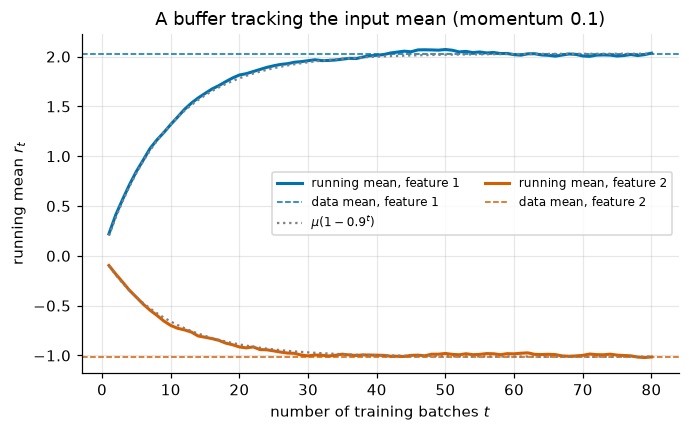

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
steps = torch.arange(1, 81)
for j, col in enumerate(COLORS[:2]):
    ax.plot(steps, history[:, j], color=col, lw=2, label=f"running mean, feature {j + 1}")
    ax.axhline(true_mean[j].item(), color=col, ls="--", lw=1, label=f"data mean, feature {j + 1}")
    ax.plot(steps, true_mean[j] * (1 - 0.9 ** steps), color="gray", ls=":", lw=1.5,
            label="$\\mu(1 - 0.9^t)$" if j == 0 else None)
ax.set_xlabel("number of training batches $t$")
ax.set_ylabel("running mean $r_t$")
ax.set_title("A buffer tracking the input mean (momentum 0.1)")
ax.legend(fontsize=8, ncol=2)
plt.show()

The running mean starts at 0 and approaches the data mean like $\mu(1 - 0.9^t)$ (dotted): unrolling the recursion with $\mathbf r_0 = 0$ gives $\mathbf r_t = m\sum_{s=1}^{t}(1-m)^{t-s}\bar{\mathbf x}_s$, and if every batch mean were exactly $\mu$, the geometric sum is $\mu(1 - (1-m)^t)$. The real curves wiggle around this because each batch of 32 has its own mean. After about 40 batches the start-up bias is gone and what remains is batch-to-batch noise.

**Buffers get no gradients.** Because the buffer was created without `requires_grad` and only updated under `no_grad`, backpropagating through the module leaves it alone:

In [22]:
center.eval()                                           # use the stored mean (Section 5)
x_req = X_shift[:4].clone().requires_grad_()            # (4, 2)
center(x_req).sum().backward()
print("grad of the input:", x_req.grad[0].tolist(), "| grad of running_mean:", center.running_mean.grad)

grad of the input: [1.0, 1.0] | grad of running_mean: None


**Persistent and non-persistent buffers.** `register_buffer(name, tensor, persistent=False)` creates a buffer that moves with the model but is **not** saved in the `state_dict`. Use it for values that can be recomputed from the configuration, such as a fixed mask, so checkpoints do not carry them around.

In [23]:
class MaskedLinear(nn.Module):
    """A linear layer whose weight is multiplied by a fixed 0/1 mask (out, in)."""
    def __init__(self, n_in, n_out):
        super().__init__()
        self.fc = nn.Linear(n_in, n_out)
        self.register_buffer("mask", torch.tril(torch.ones(n_out, n_in)), persistent=False)

    def forward(self, x):
        return x @ (self.fc.weight * self.mask).T + self.fc.bias


masked = MaskedLinear(3, 3)
print("buffers:   ", [name for name, _ in masked.named_buffers()])
print("state_dict:", list(masked.state_dict().keys()))

buffers:    ['mask']
state_dict: ['fc.weight', 'fc.bias']


### Checkpoint 3.1

Suppose every batch has exactly the same mean $\mu$. With momentum $m = 0.1$ and $\mathbf r_0 = 0$, how many batches does it take before the running mean is within 1% of $\mu$, that is, $|r_t - \mu| < 0.01|\mu|$? Derive `k_needed` (the smallest such $t$) from the formula $r_t = \mu(1 - 0.9^t)$; the check simulates `RunningCenter` to confirm.

<details>
<summary><b>💡 Hint</b></summary>

$|r_t - \mu| = 0.9^t |\mu|$, so you need $0.9^t < 0.01$, i.e. $t > \ln 0.01 / \ln 0.9$. Use `math.ceil`, and make sure the inequality is strict.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print("k_needed =", k_needed)

In [ ]:
_c = RunningCenter(1, momentum=0.1)
_batch = torch.full((8, 1), 5.0, dtype=torch.float64)
_c.double()
_close = []
for _t in range(1, 80):
    _c(_batch)
    _close.append(abs(_c.running_mean.item() - 5.0) < 0.05)
check(isinstance(k_needed, int), f"k_needed should be an int, got {type(k_needed).__name__}")
check(k_needed == _close.index(True) + 1, f"k_needed = {k_needed}, but the simulation first gets within 1% at t = {_close.index(True) + 1}")
passed("Checkpoint 3.1")

## 4. `state_dict`: the model as a dictionary of tensors

`model.state_dict()` returns an ordered dictionary from dotted names to tensors: every registered parameter and every persistent buffer, in registration order. It does **not** contain the code (the class), plain attributes like `temperature` or `momentum`, or non-persistent buffers. Saving a model means saving this dictionary; loading means building a model from the class and copying tensors into it by name.

We use a model that combines everything so far: a `RunningCenter`, then an `nn.Sequential` hidden part, then an output layer.

In [26]:
class CenteredMLP(nn.Module):
    def __init__(self, n_in=2, n_hidden=64, n_out=3):
        super().__init__()
        self.center = RunningCenter(n_in)
        self.hidden = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_hidden), nn.ReLU())
        self.out = nn.Linear(n_hidden, n_out)

    def forward(self, x):                      # x: (N, n_in)
        return self.out(self.hidden(self.center(x)))   # (N, n_out) logits


set_seed(0)
model = CenteredMLP()
sd = model.state_dict()
for name, tensor in sd.items():
    print(f"{name:32s} {str(tuple(tensor.shape)):10s} {tensor.dtype}")

center.running_mean              (2,)       torch.float32
center.num_batches_tracked       ()         torch.int64
hidden.0.weight                  (64, 2)    torch.float32
hidden.0.bias                    (64,)      torch.float32
hidden.2.weight                  (64, 64)   torch.float32
hidden.2.bias                    (64,)      torch.float32
out.weight                       (3, 64)    torch.float32
out.bias                         (3,)       torch.float32


The names follow the module tree (`hidden.2.weight` is child `"2"` of `hidden`; the `ReLU`s at indices 1 and 3 have no parameters, so they do not appear). Two facts about these tensors matter in practice:

- They are **detached** (`requires_grad=False`) but **share memory** with the live parameters. A `state_dict` is a view of the model, not a copy: if the model keeps training, the "saved" tensors in memory change too.
- `torch.save` writes them to a file, so a file is a real snapshot.

In [27]:
print("shares memory with the parameter:", sd["out.bias"].data_ptr() == model.out.bias.data_ptr(),
      "| requires_grad:", sd["out.bias"].requires_grad)
before = sd["out.bias"][0].item()
with torch.no_grad():
    model.out.bias += 1.0                               # "keep training"
print(f"sd['out.bias'][0] before: {before:.4f}, after editing the model: {sd['out.bias'][0].item():.4f}")
with torch.no_grad():
    model.out.bias -= 1.0                               # undo

shares memory with the parameter: True | requires_grad: False


sd['out.bias'][0] before: -0.1033, after editing the model: 0.8967


Now let us train the model briefly on the spirals (shifted, so the centering matters), save it to a temporary file, and load it into a **fresh** model created with a different seed.

In [28]:
def train(model, X, y, steps=2000, lr=0.3):
    """Full-batch gradient descent on cross-entropy. Returns the final loss."""
    model.train()
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        loss = F.cross_entropy(model(X), y)
        loss.backward()
        opt.step()
    return loss.item()


set_seed(0)
model = CenteredMLP()
print(f"final training loss: {train(model, X_shift, y):.4f}")
model.eval()

with tempfile.TemporaryDirectory() as tmp:
    path = os.path.join(tmp, "centered_mlp.pt")
    torch.save(model.state_dict(), path)
    n_floats = sum(t.numel() for t in model.state_dict().values())
    print(f"file size: {os.path.getsize(path)} bytes for {n_floats} numbers ({4 * n_floats} bytes as float32/int64 data)")
    loaded_sd = torch.load(path, weights_only=True)

set_seed(123)
fresh = CenteredMLP().eval()
print("fresh model, before loading: same logits?", torch.equal(fresh(X_shift), model(X_shift)))
result = fresh.load_state_dict(loaded_sd)
print("load_state_dict returned:", result)
print("fresh model, after loading:  same logits?", torch.equal(fresh(X_shift), model(X_shift)))

final training loss: 0.2023
file size: 21907 bytes for 4550 numbers (18200 bytes as float32/int64 data)
fresh model, before loading: same logits? False
load_state_dict returned: <All keys matched successfully>
fresh model, after loading:  same logits? True


After loading, the outputs are **bit-for-bit identical** (`torch.equal`, not just close): the same numbers went through the same code. The file is 21,907 bytes: the 4,550 stored numbers take about 18,200 bytes at 4 bytes each (the one `int64` counter actually takes 8), and the rest is names and structure. The temporary directory, and the file in it, are deleted when the `with` block ends.

`weights_only=True` tells `torch.load` to accept only tensors and plain containers. A `.pt` file is a Python pickle, and unpickling arbitrary data can execute arbitrary code; `weights_only=True` is the default since PyTorch 2.6, and you should keep it for files you did not create.

A `state_dict` alone is enough to reuse a trained model. To **resume training** you also need the optimizer's state (momentum buffers, step counts) and more; notebook 27 builds full checkpoints.

### Strict loading and its errors

`load_state_dict` is **strict** by default: every key in the file must match a key in the model and vice versa, with identical shapes. The error messages are worth learning to read. First, a model whose hidden width differs:

In [29]:
try:
    CenteredMLP(n_hidden=32).load_state_dict(loaded_sd)
except RuntimeError as error:
    print(error)

Error(s) in loading state_dict for CenteredMLP:
	size mismatch for hidden.0.weight: copying a param with shape torch.Size([64, 2]) from checkpoint, the shape in current model is torch.Size([32, 2]).
	size mismatch for hidden.0.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([32]).
	size mismatch for hidden.2.weight: copying a param with shape torch.Size([64, 64]) from checkpoint, the shape in current model is torch.Size([32, 32]).
	size mismatch for hidden.2.bias: copying a param with shape torch.Size([64]) from checkpoint, the shape in current model is torch.Size([32]).
	size mismatch for out.weight: copying a param with shape torch.Size([3, 64]) from checkpoint, the shape in current model is torch.Size([3, 32]).


Every mismatch is listed with both shapes: "from checkpoint" is the file, "current model" is the model you are loading into. Second, a model with the same layers under different names — for example, a refactor that renamed `out` to `classifier`:

In [30]:
class RenamedMLP(CenteredMLP):
    def __init__(self):
        super().__init__()
        self.classifier = self.out      # the same layer under a new name ...
        del self.out                    # ... and the old name removed

    def forward(self, x):
        return self.classifier(self.hidden(self.center(x)))


try:
    RenamedMLP().load_state_dict(loaded_sd)
except RuntimeError as error:
    print(error)

Error(s) in loading state_dict for RenamedMLP:
	Missing key(s) in state_dict: "classifier.weight", "classifier.bias". 
	Unexpected key(s) in state_dict: "out.weight", "out.bias". 


"Missing" keys are in the model but not in the file; "unexpected" keys are in the file but not in the model. Here the fix is to rename the keys in the dictionary, e.g. `{k.replace("out.", "classifier.", 1): v for k, v in sd.items()}`.

`strict=False` turns the key errors into a report and loads whatever matches. This is useful when you *intend* a partial load (reusing a trained body with a new head), and dangerous otherwise: a model with every key mismatched loads "successfully" and stays randomly initialized. Always inspect the returned lists. (Shape mismatches remain errors even with `strict=False`.)

In [31]:
partial = RenamedMLP()
report = partial.load_state_dict(loaded_sd, strict=False)
print("missing:   ", report.missing_keys)
print("unexpected:", report.unexpected_keys)

missing:    ['classifier.weight', 'classifier.bias']
unexpected: ['out.weight', 'out.bias']


### Checkpoint 4.1

Because a `state_dict` shares memory with the model, `best = model.state_dict()` does **not** remember the best weights seen during training. Make a real in-memory snapshot of `model` called `snapshot`: a dictionary with the same keys whose tensors are **independent copies**. The check then changes the model and restores it from your snapshot.

<details>
<summary><b>💡 Hint</b></summary>

A dictionary comprehension over `model.state_dict().items()`, calling `.clone()` on each tensor.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(set(snapshot) == set(model.state_dict()), "snapshot should have exactly the keys of model.state_dict()")
_backup = {_k: _v.clone() for _k, _v in model.state_dict().items()}
_logits = model.eval()(X_shift).detach()
with torch.no_grad():
    for _p in model.parameters():
        _p.mul_(0.5)
_changed = not torch.equal(model(X_shift), _logits)
model.load_state_dict(snapshot)
_restored = torch.equal(model(X_shift), _logits)
model.load_state_dict(_backup)                       # leave the model as it was, whatever happened
check(_changed, "the model should have changed")
check(_restored, "restoring from snapshot did not recover the original outputs: are the tensors copies?")
passed("Checkpoint 4.1")

## 5. `train()` and `eval()`

Every module has a boolean attribute `training`. `model.train()` sets it to `True` on the module **and all its descendants**; `model.eval()` is the same as `model.train(False)`. Modules created fresh start in training mode. Most layers (`nn.Linear`, `nn.ReLU`) ignore the flag; a few behave differently depending on it — our `RunningCenter`, dropout (notebook 23), and batch normalization (notebook 24).

In [34]:
def mode_report(model):
    return {name or "<root>": m.training for name, m in model.named_modules()}


model.train()
print("after train():", set(mode_report(model).values()))
model.eval()
print("after eval(): ", set(mode_report(model).values()))
model.hidden.train()                       # flags can be set on part of the tree
print("after model.hidden.train():", mode_report(model))
_ = model.eval()

after train(): {True}
after eval():  {False}
after model.hidden.train(): {'<root>': False, 'center': False, 'hidden': True, 'hidden.0': True, 'hidden.1': True, 'hidden.2': True, 'hidden.3': True, 'out': False}


Setting the mode on a subtree changes only that subtree, so a model can end up in a mixed state; calling `model.train()` or `model.eval()` on the root is the safe habit.

**`eval()` does not turn off gradient tracking.** The flag only changes how mode-dependent layers compute. Turning off the graph is `torch.no_grad()` (notebook 05); for prediction you usually want both.

In [35]:
print("eval mode, output requires_grad:", model(X_shift[:2]).requires_grad)
with torch.no_grad():
    print("eval + no_grad, output requires_grad:", model(X_shift[:2]).requires_grad)

eval mode, output requires_grad: True
eval + no_grad, output requires_grad: False


### Why the mode matters: predicting one example at a time

Our trained `CenteredMLP` contains a `RunningCenter`. In training mode it subtracts the **batch** mean. Predict a single example in training mode and the batch mean *is* that example, so the centered input is exactly $\mathbf 0$ — every example gets the same prediction. Worse, every call also moves the running mean.

In [36]:
pts = X_shift[[0, 250, 500]]                            # one point from each class, (3, 2)
model.train()
rm_before = model.center.running_mean.clone()
one_by_one_train = [model(p[None]).argmax(1).item() for p in pts]   # p[None]: a batch of one, (1, 2)
rm_moved = (model.center.running_mean - rm_before).abs().max().item()
model.eval()
one_by_one_eval = [model(p[None]).argmax(1).item() for p in pts]
print("true labels:                   ", y[[0, 250, 500]].tolist())
print("train mode, one at a time:     ", one_by_one_train, f"(running mean moved by up to {rm_moved:.3f})")
print("eval mode, one at a time:      ", one_by_one_eval)
with torch.no_grad():
    model.center.running_mean.copy_(rm_before)          # undo the drift (the counter we leave alone)

true labels:                    [0, 1, 2]
train mode, one at a time:      [2, 2, 2] (running mean moved by up to 0.107)
eval mode, one at a time:       [0, 1, 2]


In training mode the three different points get the same predicted class, and the buffer drifted. In evaluation mode each point is centered with the stored mean and classified correctly. Forgetting `model.eval()` before evaluation is one of the most common bugs in practice; with BatchNorm (notebook 24) the effect is the same in kind.

**Dropout as a black box.** `nn.Dropout(p)` is the most common mode-dependent layer. In training mode it sets each entry to 0 with probability $p$ and multiplies the survivors by $1/(1-p)$; in evaluation mode it returns its input unchanged. Notebook 23 explains why this helps; here we only watch the flag at work.

In [37]:
drop = nn.Dropout(p=0.5)
ones = torch.ones(12)
set_seed(0)
print("train mode:", drop(ones).tolist())
drop.eval()
print("eval mode: ", drop(ones).tolist())
drop.train()
avg = torch.stack([drop(ones) for _ in range(10_000)]).mean(dim=0)
print(f"train mode, average of 10,000 calls: min {avg.min().item():.3f}, max {avg.max().item():.3f}")

train mode: [0.0, 0.0, 2.0, 0.0, 0.0, 0.0, 2.0, 2.0, 0.0, 2.0, 2.0, 2.0]
eval mode:  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
train mode, average of 10,000 calls: min 0.988, max 1.018


Each entry is 0 or 2 in training mode, and the scaling makes the **average** over many calls about 1 — the evaluation-mode output. (Exercise 4 asks whether this averaging argument still holds for a whole network.)

From now on we predict with a small helper that switches to evaluation mode, turns off gradient tracking, and then **restores** the mode the model was in (so a training loop that calls it for monitoring does not continue training in evaluation mode):

In [38]:
def predict(model, X):
    """Class labels (N,) int64, computed in eval mode without tracking gradients."""
    was_training = model.training
    model.eval()
    with torch.no_grad():
        labels = model(X).argmax(dim=1)
    model.train(was_training)
    return labels


model.train()
labels_full = predict(model, X_shift)
print("still in training mode afterwards:", model.training,
      "| accuracy:", round((labels_full == y).float().mean().item(), 3),
      "| one point alone gets its batch label:", torch.equal(predict(model, X_shift[:1]), labels_full[:1]))
_ = model.eval()

still in training mode afterwards: True | accuracy: 0.953 | one point alone gets its batch label: True


### Checkpoint 5.1

By hand, before running anything: a fresh `RunningCenter(1, momentum=0.5)` receives three calls, in this order:

1. in training mode, the batch $[2, 4]$ (shape `(2, 1)`);
2. in evaluation mode, the batch $[10]$;
3. in training mode, the batch $[1]$.

Store the output of call 2 (a single number) in `out_call2`, the output of call 3 in `out_call3`, and the final `running_mean` in `r_final`. The check runs the calls.

<details>
<summary><b>💡 Hint</b></summary>

Call 1: batch mean 3, so $r = 0.5 \cdot 0 + 0.5 \cdot 3$. Call 2 uses $r$ and does not change it. Call 3: a batch of one is centered with its own mean.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_rc = RunningCenter(1, momentum=0.5)
_rc.train()
_rc(torch.tensor([[2.0], [4.0]]))
_rc.eval()
_o2 = _rc(torch.tensor([[10.0]])).item()
_rc.train()
_o3 = _rc(torch.tensor([[1.0]])).item()
check_close(out_call2, _o2, "out_call2")
check_close(out_call3, _o3, "out_call3")
check_close(r_final, _rc.running_mean.item(), "r_final")
passed("Checkpoint 5.1")

## 6. Hooks: looking inside without editing `forward`

A **hook** is a function you attach to a module (or a tensor) that PyTorch calls at a fixed moment. The three you will use most:

| Registration | Called | Signature |
| --- | --- | --- |
| `module.register_forward_hook(fn)` | after `module.forward` returns | `fn(module, inputs, output)`; `inputs` is a tuple |
| `module.register_full_backward_hook(fn)` | when gradients with respect to the module's inputs have been computed | `fn(module, grad_input, grad_output)`; both tuples |
| `tensor.register_hook(fn)` | when the gradient of `tensor` has been computed | `fn(grad)` |

Each registration returns a **handle**; `handle.remove()` detaches the hook. A forward hook that returns a value **replaces** the module's output; one that returns `None` only observes. (There is also `register_forward_pre_hook`, called before `forward` with the inputs.)

For a `nn.Linear` layer $\ell$ with output $A^{(\ell)}$, `grad_output[0]` is the upstream gradient $G = \partial L / \partial A^{(\ell)}$, shape `(N, n_ℓ)`, and `grad_input[0]` is $\partial L / \partial H^{(\ell-1)} = G\,W^{(\ell)}$ (notebook 14) — or `None` if the layer's input does not require gradients, as for the first layer, whose input is the data.

The model for this section is a three-hidden-layer ReLU MLP, built as an `nn.Sequential` with named children so the hook records are readable.

In [41]:
def make_mlp(sizes=(2, 64, 64, 64, 3)):
    """ReLU MLP with children named fc1, act1, ..., out."""
    layers = OrderedDict()
    n_hidden = len(sizes) - 2
    for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:]), start=1):
        if i <= n_hidden:
            layers[f"fc{i}"] = nn.Linear(a, b)
            layers[f"act{i}"] = nn.ReLU()
        else:
            layers["out"] = nn.Linear(a, b)
    return nn.Sequential(layers)


set_seed(0)
mlp = make_mlp()
print(mlp)

Sequential(
  (fc1): Linear(in_features=2, out_features=64, bias=True)
  (act1): ReLU()
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (act2): ReLU()
  (fc3): Linear(in_features=64, out_features=64, bias=True)
  (act3): ReLU()
  (out): Linear(in_features=64, out_features=3, bias=True)
)


First, verify that a backward hook delivers the same gradient that autograd would compute directly. We capture the output $A^{(2)}$ of `fc2` with a forward hook (and ask autograd to keep its gradient with `retain_grad()`), capture `grad_output` with a backward hook, and compare. As a third route, a forward hook can attach a **tensor** hook to the output it sees.

In [42]:
captured = {}


def keep_output(module, inputs, output):
    output.retain_grad()                                            # keep .grad of this non-leaf tensor
    output.register_hook(lambda g: captured.__setitem__("tensor_hook", g))
    captured["A2"] = output


def keep_grad(module, grad_input, grad_output):
    captured["grad_output"] = grad_output[0]
    captured["grad_input"] = grad_input[0]


handles = [mlp.fc2.register_forward_hook(keep_output), mlp.fc2.register_full_backward_hook(keep_grad)]
loss = F.cross_entropy(mlp(X), y)
loss.backward()
for h in handles:
    h.remove()

G = captured["A2"].grad                                             # (N, 64): ∂L/∂A^(2)
print("shape of ∂L/∂A2:", tuple(G.shape))
print("backward hook grad_output == retain_grad:", torch.allclose(captured["grad_output"], G))
print("tensor hook gradient       == retain_grad:", torch.allclose(captured["tensor_hook"], G))
print("grad_input == G W2 (notebook 14):        ", torch.allclose(captured["grad_input"], G @ mlp.fc2.weight))
print("hooks left on fc2:", len(mlp.fc2._forward_hooks), "forward,", len(mlp.fc2._backward_hooks), "backward")

shape of ∂L/∂A2: (600, 64)
backward hook grad_output == retain_grad: True
tensor hook gradient       == retain_grad: True
grad_input == G W2 (notebook 14):         True
hooks left on fc2: 0 forward, 0 backward


All three routes agree, and the backward formula from notebook 14 holds for `grad_input`. After `remove()`, no hooks remain.

A hook's ability to **replace** the output is powerful (and occasionally a source of confusing bugs). For instance, a hook returning `output * 0` on `act3` erases the last hidden layer, so the logits become just the output bias:

In [43]:
h = mlp.act3.register_forward_hook(lambda module, inputs, output: output * 0)
with torch.no_grad():
    print("logits of 2 points with the hook:", mlp(X[:2]).tolist(), "\noutput bias:                     ", mlp.out.bias.tolist())
h.remove()

logits of 2 points with the hook: [[0.023749127984046936, -0.02423614263534546, 0.05098463594913483], [0.023749127984046936, -0.02423614263534546, 0.05098463594913483]] 
output bias:                      [0.023749127984046936, -0.02423614263534546, 0.05098463594913483]


### A reusable activation recorder

Now the useful version. `ActivationRecorder` attaches a forward hook to every module of the chosen types and, on every forward call, stores **summary statistics** of the module's output (storing the full tensors from thousands of steps would waste memory). It also works as a context manager, so the hooks are removed even if the code inside raises an error.

In [44]:
class ActivationRecorder:
    """Record statistics of the outputs of selected modules on every forward pass.

    records[name] is a list with one dict {stat_name: float} per forward call.
    """
    def __init__(self, model, layer_types=(nn.ReLU,), stats=None):
        self.stats = stats or {
            "mean": lambda a: a.mean().item(),
            "frac_zero": lambda a: (a == 0).float().mean().item(),
        }
        self.records = {}
        self.handles = []
        for name, module in model.named_modules():
            if isinstance(module, layer_types):
                self.records[name] = []
                self.handles.append(module.register_forward_hook(self._make_hook(name)))

    def _make_hook(self, name):
        def hook(module, inputs, output):
            a = output.detach()
            self.records[name].append({k: f(a) for k, f in self.stats.items()})
        return hook

    def series(self, name, stat):
        """The recorded values of one statistic of one layer, as a tensor (calls,)."""
        return torch.tensor([r[stat] for r in self.records[name]])

    def remove(self):
        for handle in self.handles:
            handle.remove()
        self.handles = []

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.remove()

For gradients we write a matching `GradientRecorder`. It records $\|\partial L/\partial A^{(\ell)}\|$, the norm of the upstream gradient arriving at the output of each `nn.Linear`. We could use full backward hooks, but on the first layer, whose input (the data) does not require gradients, PyTorch fires them with `grad_input = (None,)` and prints a warning. The tensor-hook route verified above avoids this: a forward hook attaches a tensor hook to each output it sees.

In [45]:
class GradientRecorder:
    """Record the norm of ∂L/∂output of selected modules on every backward pass."""
    def __init__(self, model, layer_types=(nn.Linear,)):
        self.records = {}
        self.handles = []
        for name, module in model.named_modules():
            if isinstance(module, layer_types):
                self.records[name] = []
                self.handles.append(module.register_forward_hook(self._make_hook(name)))

    def _make_hook(self, name):
        def forward_hook(module, inputs, output):
            if output.requires_grad:              # e.g. not under torch.no_grad()
                output.register_hook(lambda g: self.records[name].append(g.norm().item()))
        return forward_hook

    def series(self, name):
        return torch.tensor(self.records[name])

    def remove(self):
        for handle in self.handles:
            handle.remove()
        self.handles = []

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.remove()

Train the MLP on the spirals for 2000 full-batch steps with both recorders attached, then plot what they saw. Only the training loop runs inside the `with` blocks, so the evaluation afterwards is not recorded.

In [46]:
set_seed(0)
mlp = make_mlp()
opt = torch.optim.SGD(mlp.parameters(), lr=0.3)
losses = []
with ActivationRecorder(mlp) as acts, GradientRecorder(mlp) as grads:
    for step in range(2000):
        opt.zero_grad()
        loss = F.cross_entropy(mlp(X), y)
        loss.backward()
        opt.step()
        losses.append(loss.item())
print("records per layer:", {name: len(r) for name, r in acts.records.items()}, {name: len(r) for name, r in grads.records.items()})
print("hooks left after the with block:", sum(len(m._forward_hooks) + len(m._backward_hooks) for m in mlp.modules()))
print(f"final loss {losses[-1]:.4f}, training accuracy {(predict(mlp, X) == y).float().mean().item():.3f}")

records per layer: {'act1': 2000, 'act2': 2000, 'act3': 2000} {'fc1': 2000, 'fc2': 2000, 'fc3': 2000, 'out': 2000}
hooks left after the with block: 0
final loss 0.0831, training accuracy 0.972


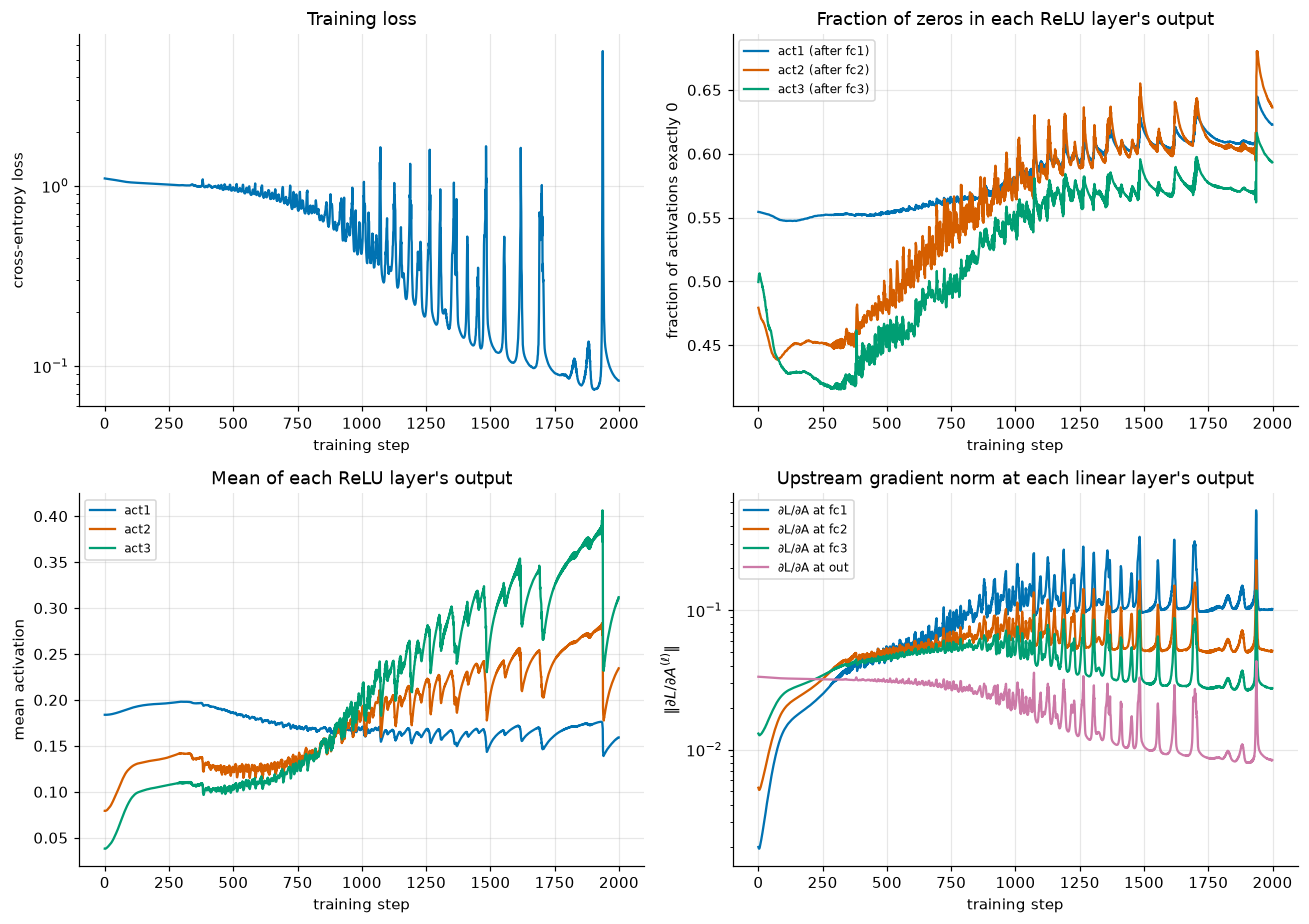

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
steps = torch.arange(len(losses))
ax = axes[0, 0]
ax.plot(steps, losses, color=COLORS[0])
ax.set_yscale("log")
ax.set_xlabel("training step")
ax.set_ylabel("cross-entropy loss")
ax.set_title("Training loss")

for k, name in enumerate(acts.records):
    axes[0, 1].plot(steps, acts.series(name, "frac_zero"), color=COLORS[k], label=f"{name} (after fc{k + 1})")
    axes[1, 0].plot(steps, acts.series(name, "mean"), color=COLORS[k], label=name)
axes[0, 1].set_xlabel("training step")
axes[0, 1].set_ylabel("fraction of activations exactly 0")
axes[0, 1].set_title("Fraction of zeros in each ReLU layer's output")
axes[0, 1].legend(fontsize=8)
axes[1, 0].set_xlabel("training step")
axes[1, 0].set_ylabel("mean activation")
axes[1, 0].set_title("Mean of each ReLU layer's output")
axes[1, 0].legend(fontsize=8)

for k, name in enumerate(grads.records):
    axes[1, 1].plot(steps, grads.series(name), color=COLORS[k], label=f"∂L/∂A at {name}")
axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("training step")
axes[1, 1].set_ylabel("$\\|\\partial L / \\partial A^{(\\ell)}\\|$")
axes[1, 1].set_title("Upstream gradient norm at each linear layer's output")
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

What the recorders show:

- **Loss (top left).** It falls from about $\ln 3$ to below 0.1 (final 0.083, training accuracy 0.972), but not smoothly: from about step 400 on there are repeated **spikes**, some above the starting loss. With plain gradient descent at $\eta = 0.3$ this network is close to the edge of stability; learning rates are the subject of notebook 19.
- **Fraction of zeros (top right).** At initialization about half of each layer's ReLU outputs are exactly 0 (0.55, 0.48 and 0.50), as expected when pre-activations are roughly symmetric around 0. During training the fraction rises to about 0.6 in every layer (0.62, 0.64, 0.59 at the end): units become more selective, each active for only part of the plane.
- **Mean activation (bottom left).** The deeper layers start with smaller activations (about 0.18, 0.08, 0.04 for layers 1–3: the signal shrinks with depth under the default initialization, a theme of notebook 18) and grow during training until layer 3 has the largest.
- **Gradient norms (bottom right).** At the start $\|\partial L/\partial A^{(\ell)}\|$ is smallest at `fc1` and largest at `out`: the gradient shrinks as it travels backward. Later the order reverses. Every spike in the loss shows up at the same step in **every** statistic of every layer, which tells us a spike is a whole-network event, not one misbehaving layer.

None of this required touching the model's code: the same recorders can be attached to any `nn.Module`.

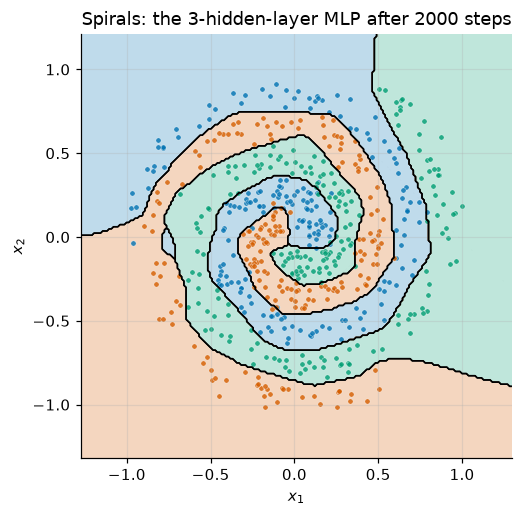

In [48]:
fig, ax = plt.subplots(figsize=(5.5, 5))
plot_decision_boundary(lambda G: predict(mlp, G), X, y, ax=ax, title="Spirals: the 3-hidden-layer MLP after 2000 steps")
plt.show()

The decision regions follow the arms. The recorders did not change the training at all: hooks that only observe leave the computation untouched. Notebooks 16 and 18 build similar recorders to study activation functions and initialization across depth.

### Checkpoint 6.1

Use forward hooks to collect the **output shape** of every `nn.Linear` in `mlp` during one forward pass on `X[:5]`. Store the shapes as tuples, in call order, in the list `linear_shapes`, and make sure **no hooks remain** on `mlp` afterwards.

<details>
<summary><b>💡 Hint</b></summary>

Loop over `mlp.modules()`, and for each `nn.Linear` keep the handle of `m.register_forward_hook(lambda mod, inp, out: linear_shapes.append(tuple(out.shape)))`. After the forward pass, call `remove()` on every handle.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(linear_shapes)

In [ ]:
check(linear_shapes == [(5, 64), (5, 64), (5, 64), (5, 3)],
      f"linear_shapes = {linear_shapes}, expected [(5, 64), (5, 64), (5, 64), (5, 3)]")
_left = sum(len(m._forward_hooks) for m in mlp.modules())
check(_left == 0, f"{_left} forward hook(s) are still attached to mlp")
passed("Checkpoint 6.1")

## 7. Initialization and editing parameters

### `apply`: visit every module

`model.apply(fn)` calls `fn(m)` on every submodule and finally on the model itself, children before parents, and returns the model. It is the standard way to re-initialize all layers of one type.

In [51]:
visited = []
make_mlp((2, 4, 3)).apply(lambda m: visited.append(type(m).__name__))
print("apply visits:", visited)

apply visits: ['Linear', 'ReLU', 'Linear', 'Sequential']


The root `Sequential` comes last. A common use is to replace the default initialization. `nn.Linear(n_in, n_out)` initializes both weight and bias uniformly in $[-1/\sqrt{n_\text{in}},\, 1/\sqrt{n_\text{in}}]$ (stated from the PyTorch source; checked numerically below). Notebook 18 derives better choices; here we only practise the mechanics, initializing all weights from $\mathcal N(0, 0.01^2)$ and all biases to 0 with the functions in `nn.init`, which modify tensors in place without recording gradients.

In [52]:
def init_small(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, mean=0.0, std=0.01)
        nn.init.zeros_(m.bias)


set_seed(0)
fresh_mlp = make_mlp()
bounds_ok = all(m.weight.abs().max() <= 1 / math.sqrt(m.in_features) for m in fresh_mlp.modules() if isinstance(m, nn.Linear))
print("default init within ±1/sqrt(fan_in) for every layer:", bounds_ok)
with torch.no_grad():
    print(f"initial loss, default init: {F.cross_entropy(fresh_mlp(X), y).item():.4f}")
    fresh_mlp.apply(init_small)
    print(f"initial loss, init_small:   {F.cross_entropy(fresh_mlp(X), y).item():.4f}   (ln 3 = {math.log(3):.4f})")

default init within ±1/sqrt(fan_in) for every layer: True
initial loss, default init: 1.0987
initial loss, init_small:   1.0986   (ln 3 = 1.0986)


With tiny weights the logits are all near 0, so the initial loss is almost exactly $\ln K$ — the sanity check from notebook 13. (Such small weights in a deep network make the signal shrink layer after layer; notebook 18 measures this.)

### Editing parameters in place

A parameter is a leaf tensor with `requires_grad=True`, and autograd forbids in-place changes to such tensors while gradients are being tracked, because the change would not be part of any graph (notebook 05). Edits therefore go inside `torch.no_grad()`, exactly like the update step in our raw-tensor training loop:

In [53]:
layer = nn.Linear(2, 3)
try:
    layer.weight.mul_(2.0)
except RuntimeError as error:
    print("RuntimeError:", error)
with torch.no_grad():
    layer.weight.mul_(2.0)
    layer.bias.fill_(0.0)
print("after the no_grad edit, bias =", layer.bias.tolist(), "| still a Parameter:", isinstance(layer.bias, nn.Parameter))

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.
after the no_grad edit, bias = [0.0, 0.0, 0.0] | still a Parameter: True


Note the difference between **editing** and **replacing**: `layer.bias.fill_(0)` changes the registered tensor, so an optimizer already holding it sees the change. `layer.bias = nn.Parameter(torch.zeros(3))` registers a *new* tensor, and an optimizer created earlier would keep updating the old one.

### Freezing parameters

`p.requires_grad_(False)` **freezes** a parameter: autograd computes no gradient for it, so its `.grad` stays `None`, and `torch.optim` optimizers skip parameters whose `.grad` is `None`. This is how a trained part of a model is kept fixed while another part is trained (fine-tuning, Chapter 9). Freeze the hidden layers of the trained `mlp`, re-initialize its output layer, and retrain only that layer:

In [54]:
for name, p in mlp.named_parameters():
    if not name.startswith("out."):
        p.requires_grad_(False)
n_trainable = sum(p.numel() for p in mlp.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable} of {sum(p.numel() for p in mlp.parameters())}")

frozen_before = {name: p.clone() for name, p in mlp.named_parameters() if not p.requires_grad}
set_seed(1)
mlp.out.reset_parameters()                                         # nn.Linear's default initialization again
print(f"accuracy with a re-initialized output layer: {(predict(mlp, X) == y).float().mean().item():.3f}")
opt = torch.optim.SGD(mlp.parameters(), lr=0.3)                    # given ALL parameters, on purpose
for _ in range(300):
    opt.zero_grad()
    F.cross_entropy(mlp(X), y).backward()
    opt.step()
print(f"accuracy after retraining only the output layer: {(predict(mlp, X) == y).float().mean().item():.3f}")
print("frozen parameters unchanged:", all(torch.equal(p, frozen_before[n]) for n, p in mlp.named_parameters() if not p.requires_grad))
print("their .grad:", {n: p.grad for n, p in mlp.named_parameters() if not p.requires_grad and n.startswith("fc1")})

trainable parameters: 195 of 8707
accuracy with a re-initialized output layer: 0.237
accuracy after retraining only the output layer: 0.972
frozen parameters unchanged: True
their .grad: {'fc1.weight': None, 'fc1.bias': None}


The frozen layers did not move by a single bit even though the optimizer was given every parameter, and retraining only the 195 output-layer parameters on top of the frozen, already-trained features recovers the accuracy quickly. The cleaner habit is to give the optimizer only the trainable parameters, `[p for p in model.parameters() if p.requires_grad]`.

### Checkpoint 7.1

Write `freeze_except(model, prefix)` that freezes every parameter whose name does **not** start with `prefix` and makes every parameter whose name does start with `prefix` trainable. It should return the number of trainable values (elements, not tensors).

<details>
<summary><b>💡 Hint</b></summary>

Loop over `model.named_parameters()` and call `p.requires_grad_(name.startswith(prefix))`. Then sum `p.numel()` over the trainable ones.

</details>

In [ ]:
def freeze_except(model, prefix):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_m = make_mlp()
check(freeze_except(_m, "fc3.") == 64 * 65, "freeze_except(make_mlp(), 'fc3.') should return 4160")
check(not _m.fc1.weight.requires_grad and _m.fc3.weight.requires_grad and _m.fc3.bias.requires_grad, "only fc3 should be trainable")
check(freeze_except(_m, "") == 8707, "prefix '' should make every parameter trainable again (8707 values)")
check(all(p.requires_grad for p in _m.parameters()), "every parameter should be trainable after freeze_except(model, '')")
passed("Checkpoint 7.1")

## 8. Dtype and device: one call for the whole tree

`model.to(dtype)` and `model.to(device)` convert or move every registered parameter **and buffer**, recursively. Unlike `tensor.to`, which returns a new tensor, `module.to` modifies the module in place and returns the same object (so `model = model.to(device)` and `model.to(device)` are equivalent). Converting the dtype only affects floating-point tensors: our integer counter stays `int64`. And a plain-tensor attribute, being invisible to the module, is not converted at all.

In [57]:
cm = CenteredMLP()
cm.plain = torch.zeros(2)                                    # not registered
returned = cm.to(torch.float64)
print("module.to returns the same object:", returned is cm)
print("out.weight:", cm.out.weight.dtype, "| center.running_mean:", cm.center.running_mean.dtype,
      "| num_batches_tracked:", cm.center.num_batches_tracked.dtype, "| plain attribute:", cm.plain.dtype)
print("float64 forward pass works:", cm(X_shift.double()).dtype)

module.to returns the same object: True
out.weight: torch.float64 | center.running_mean: torch.float64 | num_batches_tracked: torch.int64 | plain attribute: torch.float32
float64 forward pass works: torch.float64


Converting a whole model to `float64` is how you would run `torch.autograd.gradcheck` on it (notebooks 05 and 14). The device version works the same way. On a GPU machine, the cell below moves the trained `CenteredMLP` from Section 4, checks where its parameters and buffers live, and compares predictions. (Apple's MPS backend does not support `float64`; keep double-precision work on the CPU.)

In [58]:
if device.type == "cpu":
    print("No GPU selected; skipping. (Set up Colab with a GPU runtime to try this.)")
else:
    model_cpu = CenteredMLP()
    model_cpu.load_state_dict(model.state_dict())
    model_cpu.eval()
    model_dev = CenteredMLP().eval()
    model_dev.load_state_dict(model.state_dict())
    model_dev.to(device)
    print("parameter devices:", {p.device.type for p in model_dev.parameters()},
          "| buffer devices:", {b.device.type for b in model_dev.buffers()})
    with torch.no_grad():
        logits_cpu = model_cpu(X_shift)
        logits_dev = model_dev(X_shift.to(device)).cpu()
    print(f"max |CPU logits − {device.type.upper()} logits| = {(logits_cpu - logits_dev).abs().max().item():.2e}")
    print("same predicted classes:", torch.equal(logits_cpu.argmax(1), logits_dev.argmax(1)))
    try:
        model_dev(X_shift)                                    # input still on the CPU
    except RuntimeError as error:
        print("RuntimeError:", str(error)[:150])

parameter devices: {'mps'} | buffer devices: {'mps'}
max |CPU logits − MPS logits| = 7.63e-06
same predicted classes: True
RuntimeError: Expected all tensors to be on the same device, but found at least two devices, mps:0 and cpu!


On an accelerator the logits agree with the CPU's to within floating-point rounding (different kernels add in different orders, notebook 00), and the predictions match. Feeding a CPU tensor to a model on another device is an error: input and model must share a device.

## Exercises

### Exercise 1 (modify): record a different statistic

The cell below trains the same 3-hidden-layer MLP as Section 6 with an `ActivationRecorder` whose `stats` dictionary decides what is recorded, and plots every recorded statistic for every layer. It currently records only the fraction of zeros.

1. Add two statistics: `"max"`, the largest activation in the batch, and `"rms"`, the root-mean-square activation $\sqrt{\operatorname{mean}(a^2)}$. Run the cell.
2. How do the maximum and RMS activations of the three layers change during training, and how do the layers compare? Is the largest activation a good summary of a typical activation?
3. Replace `layer_types=(nn.ReLU,)` with `layer_types=(nn.Linear,)`, so the statistics describe the pre-activations $A^{(\ell)}$ (including the logits). What does `"frac_zero"` show now, and why?

Answer in the markdown cell below.

<details>
<summary><b>💡 Hint</b></summary>

Each statistic is a function of the detached output tensor `a` returning a Python float: `lambda a: a.max().item()` and `lambda a: a.pow(2).mean().sqrt().item()`. For part 3: how likely is a pre-activation computed from floating-point inputs to be exactly 0?

</details>

frac_zero act1 : step 0    0.554   step 1999    0.623
frac_zero act2 : step 0    0.479   step 1999    0.636
frac_zero act3 : step 0    0.500   step 1999    0.593


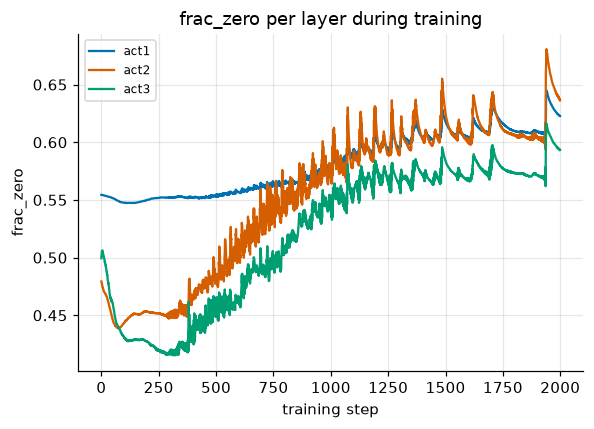

In [59]:
stats_ex1 = {
    "frac_zero": lambda a: (a == 0).float().mean().item(),
}
layer_types_ex1 = (nn.ReLU,)

set_seed(0)
mlp_ex1 = make_mlp()
opt_ex1 = torch.optim.SGD(mlp_ex1.parameters(), lr=0.3)
with ActivationRecorder(mlp_ex1, layer_types=layer_types_ex1, stats=stats_ex1) as rec_ex1:
    for _ in range(2000):
        opt_ex1.zero_grad()
        F.cross_entropy(mlp_ex1(X), y).backward()
        opt_ex1.step()

fig, axes = plt.subplots(1, len(stats_ex1), figsize=(5.5 * len(stats_ex1), 4), squeeze=False)
for ax, stat in zip(axes[0], stats_ex1):
    for k, name in enumerate(rec_ex1.records):
        values = rec_ex1.series(name, stat)
        ax.plot(values, color=COLORS[k], label=name)
        print(f"{stat:9s} {name:5s}: step 0 {values[0].item():8.3f}   step 1999 {values[-1].item():8.3f}")
    ax.set_xlabel("training step")
    ax.set_ylabel(stat)
    ax.set_title(f"{stat} per layer during training")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

*Your answer:*

### Exercise 2 (implement): a `Standardize` module

Notebook 06 showed that standardizing features (subtracting the mean, dividing by the standard deviation) makes gradient descent much better conditioned. Package this as a module whose statistics are **buffers**, so they are saved and moved with the model, but never trained:

- `Standardize(num_features, eps=1e-8)`: buffers `mean` (initialized to zeros) and `std` (initialized to ones), both of shape `(num_features,)`, and no parameters.
- `fit(X)`: set `mean` and `std` to the per-feature mean and standard deviation of `X` (shape `(N, num_features)`), using `X.std(dim=0)` with its default correction. It must not build an autograd graph, must update the existing buffers (not create new attributes), and must return `self`.
- `forward(x)`: return `(x - mean) / (std + eps)`.

<details>
<summary><b>💡 Hint</b></summary>

In `__init__`: `self.register_buffer("mean", torch.zeros(num_features))`, likewise `std`, and store `self.eps`. In `fit`: inside `with torch.no_grad():`, `self.mean.copy_(X.mean(dim=0))` and `self.std.copy_(X.std(dim=0))`. Copying in place keeps the buffers registered (assigning `self.mean = ...` with a tensor would also work, because the name is already a buffer).

</details>

In [ ]:
class Standardize(nn.Module):
    def __init__(self, num_features, eps=1e-8):
        super().__init__()
        # YOUR CODE HERE
        raise NotImplementedError

    def fit(self, X):
        # YOUR CODE HERE
        raise NotImplementedError

    def forward(self, x):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
_s = Standardize(2)
check(len(list(_s.parameters())) == 0, "Standardize should have no parameters")
check(sorted(_s.state_dict().keys()) == ["mean", "std"], f"state_dict keys {sorted(_s.state_dict().keys())}, expected ['mean', 'std']")
check_close(_s(X_shift), X_shift, "output before fit (mean 0, std 1)")
_Xg = X_shift.clone().requires_grad_()
check(_s.fit(_Xg) is _s, "fit should return self")
check(not _s.mean.requires_grad and not _s.std.requires_grad, "fit should not build a graph: the buffers require grad")
check(sorted(n for n, _ in _s.named_buffers()) == ["mean", "std"], "mean and std should still be registered buffers after fit")
_Z = _s(X_shift)
check_close(_Z.mean(dim=0), torch.zeros(2), "mean of standardized data", atol=1e-5)
check_close(_Z.std(dim=0), torch.ones(2), "std of standardized data", atol=1e-5)
_s2 = Standardize(2)
_s2.load_state_dict(_s.state_dict())
check(torch.equal(_s2(X_shift), _Z), "a fresh Standardize loaded from the state_dict should give identical outputs")
_s2.to(torch.float64)
check(_s2.mean.dtype == torch.float64, "the buffers should follow .to(torch.float64)")
passed("Exercise 2")

### Exercise 3 (debug): a layer that never learns

`SpiralClassifier` should be a 2 → 64 → 64 → 3 ReLU network. The buggy version (in the comments) runs and trains without any error, yet calling it twice on the same input gives different outputs and its loss never moves away from about $\ln 3$. Find the bug and write the corrected class.

<details>
<summary><b>💡 Hint</b></summary>

Count the parameters the buggy model registers and compare with `count_mlp_params([2, 64, 64, 3])`. Where is the output layer created, and how often?

</details>

In [ ]:
# Buggy version:
#     class SpiralClassifier(nn.Module):
#         def __init__(self, n_hidden=64, n_classes=3):
#             super().__init__()
#             self.n_classes = n_classes
#             self.body = nn.Sequential(nn.Linear(2, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_hidden), nn.ReLU())
#
#         def forward(self, x):
#             head = nn.Linear(self.body[2].out_features, self.n_classes)
#             return head(self.body(x))
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
set_seed(0)
_clf = SpiralClassifier()
_n = sum(p.numel() for p in _clf.parameters())
check(_n == 4547, f"the model registers {_n} parameters; a 2 → 64 → 64 → 3 MLP has 4547")
with torch.no_grad():
    check(torch.equal(_clf(X), _clf(X)), "two calls on the same input should give the same output")
_final = train(_clf, X, y, steps=2000, lr=0.3)
_acc = (predict(_clf, X) == y).float().mean().item()
check(_acc > 0.9, f"training accuracy {_acc:.3f} after 2000 steps; expected above 0.9")
passed("Exercise 3")

For comparison, here is the buggy version trained in exactly the same way:

In [64]:
class BuggySpiralClassifier(nn.Module):
    def __init__(self, n_hidden=64, n_classes=3):
        super().__init__()
        self.n_classes = n_classes
        self.body = nn.Sequential(nn.Linear(2, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_hidden), nn.ReLU())

    def forward(self, x):
        head = nn.Linear(self.body[2].out_features, self.n_classes)
        return head(self.body(x))


set_seed(0)
buggy = BuggySpiralClassifier()
print("registered parameters:", sum(p.numel() for p in buggy.parameters()))
with torch.no_grad():
    print("two calls on the same input agree:", torch.equal(buggy(X[:5]), buggy(X[:5])))
with torch.no_grad():
    print(f"loss before training: {F.cross_entropy(buggy(X), y).item():.4f}")
print(f"loss after 2000 steps: {train(buggy, X, y, steps=2000, lr=0.3):.4f}")
print(f"training accuracy: {(predict(buggy, X) == y).float().mean().item():.3f}")

registered parameters: 4352
two calls on the same input agree: False
loss before training: 1.0989


loss after 2000 steps: 1.1006
training accuracy: 0.318


### Exercise 4 (investigate): is evaluation mode the average of training mode?

Section 5 showed that for a single `nn.Dropout`, the average of many training-mode outputs approaches the evaluation-mode output. Does this still hold for a network? The scaffold builds two small networks with the same weights except for where dropout sits:

- **A**: `Linear → ReLU → Linear → ReLU → Dropout → Linear` (dropout only directly before the last, linear layer);
- **B**: `Linear → ReLU → Dropout → Linear → ReLU → Linear` (dropout earlier, followed by another nonlinearity).

For 200 inputs it compares the evaluation-mode output with the average of $S$ training-mode outputs, for several $S$, and reports the largest absolute gap. Run it and answer in the markdown cell:

1. For each network, does the gap shrink toward 0 as $S$ grows? At what rate?
2. Explain the difference between A and B. (Hint: what is $E[W(\mathbf m \odot \mathbf h)/(1-p)]$ for a random 0/1 mask $\mathbf m$, and what is $E[\operatorname{relu}(\cdot)]$ of a random quantity?)
3. Optionally, change `p` and see how the gap for B depends on it. Or try **C**: `Linear → Dropout → ReLU → Linear → ReLU → Linear`, dropout *before* the first ReLU — and explain what you find.

<details>
<summary><b>💡 Hint</b></summary>

Averaging $S$ independent random outputs has a Monte Carlo error that falls like $1/\sqrt S$ (notebook 04). Expectation passes through linear maps, $E[W\mathbf v] = W E[\mathbf v]$, but not through nonlinear ones: in general $E[\operatorname{relu}(v)] \neq \operatorname{relu}(E[v])$.

</details>

net A: typical |eval output| 0.094; max gap for S = 10: 0.0833, 100: 0.0292, 1000: 0.0097, 10000: 0.0035


net B: typical |eval output| 0.094; max gap for S = 10: 0.1314, 100: 0.0931, 1000: 0.0831, 10000: 0.0816


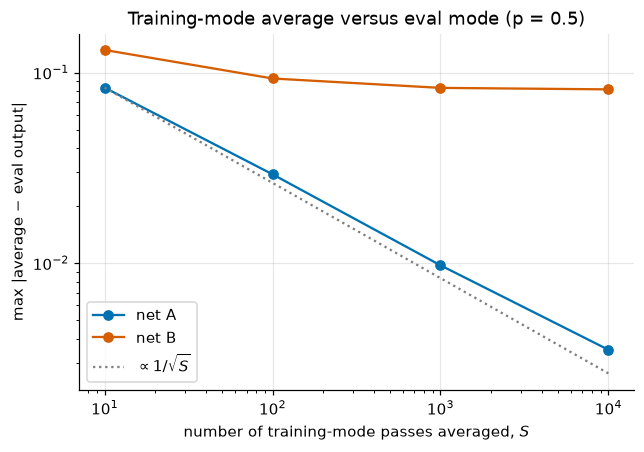

In [65]:
p = 0.5
set_seed(0)
lin1, lin2, lin3 = nn.Linear(2, 64), nn.Linear(64, 64), nn.Linear(64, 3)    # shared by both networks
net_A = nn.Sequential(lin1, nn.ReLU(), lin2, nn.ReLU(), nn.Dropout(p), lin3)
net_B = nn.Sequential(lin1, nn.ReLU(), nn.Dropout(p), lin2, nn.ReLU(), lin3)
X_ex4 = X[torch.randperm(N)[:200]]                               # (200, 2)

S_values = [10, 100, 1000, 10_000]
gaps = {"A": [], "B": []}
with torch.no_grad():
    for label, net in [("A", net_A), ("B", net_B)]:
        net.eval()
        out_eval = net(X_ex4)                                    # (200, 3)
        net.train()
        set_seed(1)
        total, done = torch.zeros_like(out_eval), 0
        for S in S_values:
            while done < S:
                total += net(X_ex4)
                done += 1
            gaps[label].append((total / S - out_eval).abs().max().item())
        print(f"net {label}: typical |eval output| {out_eval.abs().mean().item():.3f}; max gap for S = "
              + ", ".join(f"{S}: {g:.4f}" for S, g in zip(S_values, gaps[label])))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for k, label in enumerate(gaps):
    ax.loglog(S_values, gaps[label], "o-", color=COLORS[k], label=f"net {label}")
ax.loglog(S_values, [gaps["A"][0] * math.sqrt(S_values[0] / S) for S in S_values], ":", color="gray", label="$\\propto 1/\\sqrt{S}$")
ax.set_xlabel("number of training-mode passes averaged, $S$")
ax.set_ylabel("max |average − eval output|")
ax.set_title(f"Training-mode average versus eval mode (p = {p})")
ax.legend()
plt.show()

*Your conclusion:*

## Summary and what's next

- A module is a class with `__init__` (call `super().__init__()` first) and `forward`. Call the module, `model(x)`, so that `__call__` runs hooks around `forward`.
- **Registration** happens in `__setattr__`: an `nn.Parameter` goes into `_parameters`, an `nn.Module` into `_modules`, anything else into the plain `__dict__`. `parameters()`, `named_parameters()`, `children()` and `modules()` walk the tree. A plain tensor or a Python list of layers is **not** registered: not trained, not saved, not moved. `nn.ModuleList`, `nn.ModuleDict` and `nn.Sequential` register their contents.
- **Buffers** (`register_buffer`) hold non-trainable state such as running statistics: saved in the `state_dict` (unless `persistent=False`) and moved by `.to()`, but never returned by `parameters()` and given no gradients.
- The **`state_dict`** maps dotted names to tensors — parameters and persistent buffers, not code or plain attributes. Its tensors share memory with the model (clone for a snapshot). `torch.save`/`torch.load(weights_only=True)` round-trip it exactly; strict loading reports missing keys, unexpected keys and shape mismatches by name.
- **`train()`/`eval()`** set the `training` flag on the whole subtree. It changes how mode-dependent layers compute (our `RunningCenter`; dropout; BatchNorm) and does not disable gradients. Predicting in training mode can silently give wrong answers and corrupt buffers.
- **Hooks** observe (or modify) outputs and gradients without touching `forward`: forward hooks see `(module, inputs, output)`, full backward hooks see `grad_input` and `grad_output = ∂L/∂output`, tensor hooks see a tensor's gradient. Keep the handles and remove them. With them we recorded per-layer activation and gradient statistics throughout training.
- `apply` re-initializes every layer; in-place parameter edits go inside `torch.no_grad()`; `requires_grad_(False)` freezes parameters, which optimizers then leave unchanged; `module.to(dtype or device)` converts every parameter and buffer in place.

We now have the tools to see inside a network. Notebook 16 uses them on the piece of the MLP we have taken for granted so far, the **activation function**: sigmoid, tanh, ReLU and its relatives, their derivatives, how they saturate, and how many ReLU units die during training — measured with hooks like the ones built here.